# Visualize Model Predictions

This notebook loads a trained model and visualizes its predictions on a new sample.

In [97]:
import sys
import json
import random
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import napari
from scipy.interpolate import griddata
from pathlib import Path

from plot_utils_era5 import *

project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(Path.cwd().parent / 'scripts'))

sys.path.append(f"{project_root}src/")
# Import utilities
from utilities import KernelNN, KernelNN_subgraph, setup_device, get_output_affinities
from plot_utilities import plot_results_napari, plot_results_matplotlib

# Device setup
device = setup_device()
print(f'Using device: {device}')

from sklearn.decomposition import PCA
import time
from IPython.display import display
import plotly.express as px


figsize = (7, 7)

FileNotFoundError: [Errno 2] No such file or directory

In [ ]:
def load_model(id:str, model_type:str='random_crop'):
    model_path = project_root / 'ERA5' / 'trained_models' / model_type / id
    with open(model_path, 'r') as f:
        config = json.load(f)
    model = KernelNN(
        width=config['width'],
        ker_width=config['ker_width'],
        depth=config['depth'],
        ker_in=config['edge_attr'],
        in_width=config['node_features'],
        out_width=config['out_width']
    ).to(device)
    return model
    

In [95]:
os.system("rsync -r springfield:~/new/NOFE/ERA5/trained_models/* ../trained_models/")

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
rsync: [Receiver] getcwd(): No such file or directory (2)
rsync error: errors selecting input/output files, dirs (code 3) at util1.c(1162) [Receiver=3.4.1]


768

In [4]:
# choose data
model_type = 'regular'


# ---------------------------------------------------------------------------
sys.path.append(f"{project_root}/ERA5/scripts/")
from utilities_era5 import ERA5_Graph_Generator as Data_Generator
from utilities_era5 import ERA5_Graph_Generator_perSampleNorm as Data_Generator_old



# Paths
trained_models_path = project_root / 'ERA5' / 'trained_models' / model_type
training_logs_path = trained_models_path / 'logs'
data_path = project_root.parent / 'ERA5' / 'data'  # Adjust if needed

print('Available models:\n')
files = sorted(os.listdir(trained_models_path), reverse=True)

for i, f in enumerate(files):
    if Path(f).suffix == ".pth":
        print(f'[{i}] {f}')


using Device: mps
Available models:

[0] testmodel8_w64_kw128_d6-regular-2026-04-14_t21-23-08.pth
[1] testmodel8_w64_kw128_d6-regular-2026-04-14_t14-25-44.pth
[2] testmodel7_w64_kw128_d3-regular-2026-04-14_t20-14-16.pth
[3] testmodel7_w64_kw128_d3-regular-2026-04-14_t13-56-50.pth
[4] testmodel6_w64_kw32_d6-regular-2026-04-14_t21-35-53.pth
[5] testmodel6_w64_kw32_d6-regular-2026-04-14_t13-45-23.pth
[6] testmodel5_w64_kw32_d3-regular-2026-04-14_t20-59-30.pth
[7] testmodel5_w64_kw32_d3-regular-2026-04-14_t13-23-20.pth
[8] testmodel4_w8_kw128_d6-regular-2026-04-14_t20-14-16.pth
[9] testmodel4_w8_kw128_d6-regular-2026-04-14_t13-00-13.pth
[10] testmodel3_w8_kw128_d3-regular-2026-04-14_t21-21-07.pth
[11] testmodel3_w8_kw128_d3-regular-2026-04-14_t13-40-33.pth
[12] testmodel2_w8_kw32_d6-regular-2026-04-14_t20-43-00.pth
[13] testmodel2_w8_kw32_d6-regular-2026-04-14_t13-17-37.pth
[14] testmodel1_w8_kw32_d3-regular-2026-04-15_t10-12-45.pth
[15] testmodel1_w8_kw32_d3-regular-2026-04-14_t20-14-16.p

## 2. Load Model and Configuration

In [5]:
# Set model ID
model_id = 'test1_model5_median_2026-04-21_t20-42-15'
# model_id = files[19]#'reg_medium_woPos_deep6-regular-2026-04-13_t18-58-47'



# ---------------------------------------------------------------------------
if model_id.endswith('.pth'):
    model_id = model_id[:-4]

# Load full configuration (includes model, dataset, and training configs)
config_path = f'{training_logs_path}/configs/{model_id}.json'
with open(config_path, 'r') as f:
    config = json.load(f)

# Load loss records
loss_df = pd.read_csv(f'{training_logs_path}/loss_records/{model_id}.csv')

print('Configuration:')
for key, value in config.items():
    print(f'  {key}: {value}')

print(f'\Training completed {len(loss_df)} epochs')
print(f'Final training loss: {loss_df["loss"].iloc[-1]:.4f}')
print(f'Final validation loss: {loss_df["val_loss"].iloc[-1]:.4f}')

Configuration:
  model_config_path: ERA5/configurations/regular/model_configs/testmodel5_w64_kw32_d3_wPos.json
  dataset_id: dataset_reg_fixcrop_median_wPos
  dataset_path: ERA5/datasets/regular
  learning_rate: 5e-05
  scheduler_step: 5
  scheduler_gamma: 0.9
  epochs: 100
  random_seed: 42
  use_gradient_clipping: True
  track_gradients: True
  checkpoint_every: 5
  width: 64
  ker_width: 32
  depth: 3
  node_features: 14
  edge_attr: 7
  out_width: 3
  data_folder_path: ../data/
  dataset_save_path: ../datasets/regular/
  lat_min: 30
  lat_max: 75
  lon_min: -12
  lon_max: 33
  N_min: 500
  N_max: 10000
  k: 10
  perplexity: 10
  sampling_method: random
  train_date_start_end: ['2018-01-01', '2018-12-31']
  test_date_start_end: ['2019-01-01', '2019-01-31']
  train_samples_per_date: 10
  test_samples_per_date: 5
  feature_mode: channel_and_position
  sigma_method: global_median
  vars: ['w', 'v', 'z', 'q', 'r', 't', 'd', 'o3', 'pv', 'u', 'vo']
\Training completed 101 epochs
Final tra

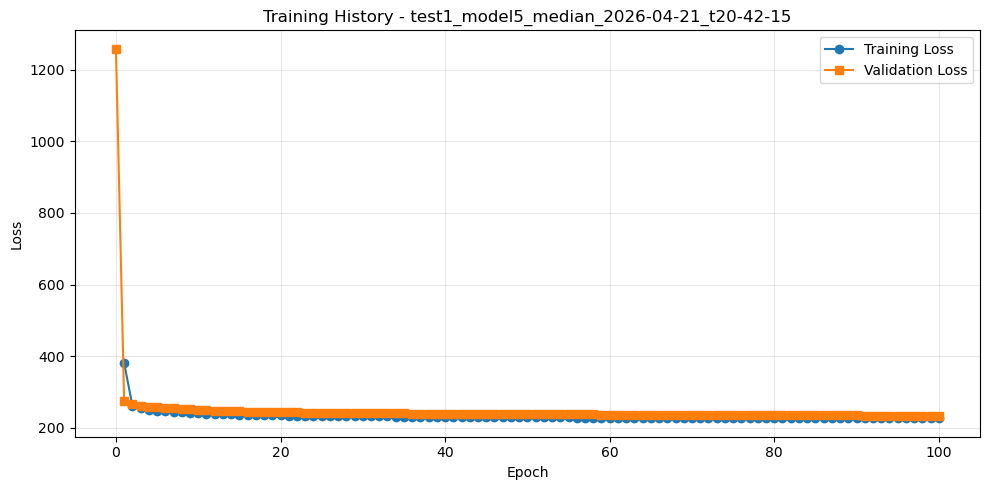

In [6]:
# Plot training history
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(loss_df['epoch'], loss_df['loss'], label='Training Loss', marker='o')
ax.plot(loss_df['epoch'], loss_df['val_loss'], label='Validation Loss', marker='s')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title(f'Training History - {model_id}')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
lat_min = config["lat_min"]
lat_max = config["lat_max"]
lon_min = config["lon_min"]
lon_max = config["lon_max"]
#N = config["N"]
k = config["k"]
perplexity = config["perplexity"]
sampling_method = config["sampling_method"]
train_date_start_end = config["train_date_start_end"]
test_date_start_end = config["test_date_start_end"]
train_samples_per_date = config["train_samples_per_date"]
test_samples_per_date = config["test_samples_per_date"]
feature_mode = config["feature_mode"]
vars = config["vars"]


In [8]:
model = KernelNN(
    width=config['width'],
    ker_width=config['ker_width'],
    depth=config['depth'],
    ker_in=config['edge_attr'],
    in_width=config['node_features'],
    out_width=config['out_width']
).to(device)

# Load trained weights
model_path = f'{trained_models_path}/{model_id}.pth'
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

print(f'Model loaded: {model_id}')
print(f'Total parameters: {sum(p.numel() for p in model.parameters()):,}')

Model loaded: test1_model5_median_2026-04-21_t20-42-15
Total parameters: 141,795


## 3. Create New Sample

Use the same functionality as dataset creation to generate a single sample.

In [86]:
date = "2019-01-15"

#bbox = lon_min, lat_min, lon_max, lat_max
bbox = -12, 30, 33, 75
Generator = Data_Generator_old(data_path)
#Generator = Data_Generator(data_path)
Generator.load_data(bbox=bbox, vars=vars, filename=f'{date}.nc')
print(f'total points available: {Generator.da.shape[1]*Generator.da.shape[2]}')

N=15000
print('generate data')
graph = Generator.sample_graph(N=N, k=k, perplexity=perplexity, sampling_method=sampling_method, gen_feature_mode=feature_mode, sigma_method=config['sigma_method'])
sample = graph.to(device)

locations = pd.DataFrame({"lat": sample.meta.gps[:,0], "lon": sample.meta.gps[:,1]})

total points available: 32761
generate data


In [79]:
graph.normed_values.shape

torch.Size([15000, 11])

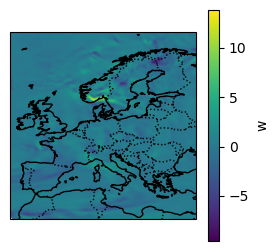

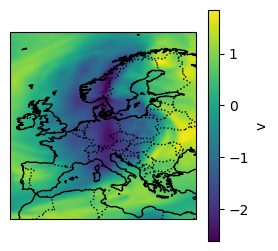

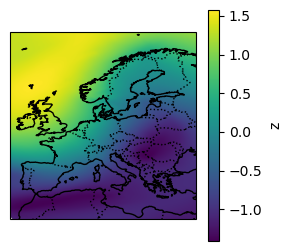

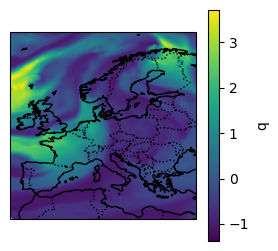

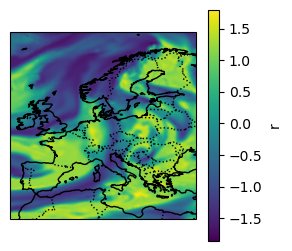

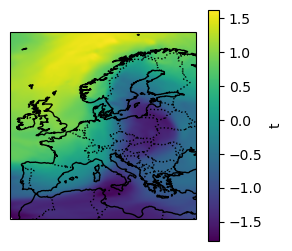

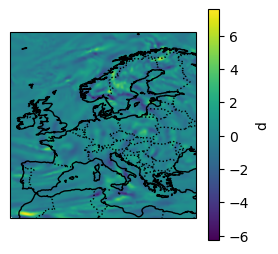

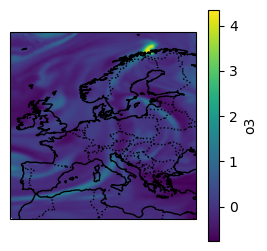

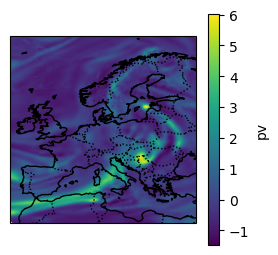

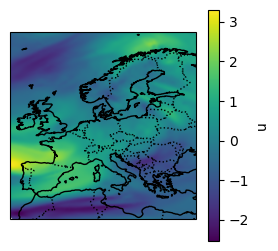

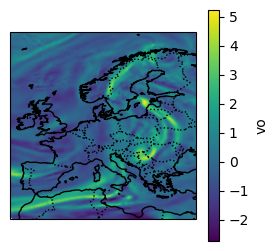

In [93]:
for i, var in enumerate(config['vars']):
    dat = pd.DataFrame({var: graph.normed_values[:,i].detach().cpu().numpy()})
    dat = pd.concat([locations, dat], axis=1)
    fig = scalar_plot(dat, var, figsize=(3,3))

In [ ]:
print('predict results')
output = model(sample).detach().cpu().numpy()

In [50]:
aff_in = graph.input_affinities.detach().cpu().numpy()
aff_out = get_output_affinities(torch.from_numpy(output).to(device='mps'), graph.edge_index).detach().cpu().numpy()

# example input (replace with your array)
X = sample.x.detach().cpu().numpy() # shape: (samples, features)

# apply PCA to reduce to 3 dimensions
pca = PCA(n_components=3)
X_reduced = pca.fit_transform(X)
aff_pca = get_output_affinities(torch.from_numpy(X_reduced).to(device='mps'), graph.edge_index).detach().cpu().numpy()

---
Plot

In [73]:
graph.sigmas.mean()

tensor(0.7196, device='mps:0')

# Visualize affinities

In [59]:
affinities = {"input" : aff_in,
              "output": aff_out,
              "pca": aff_pca,}

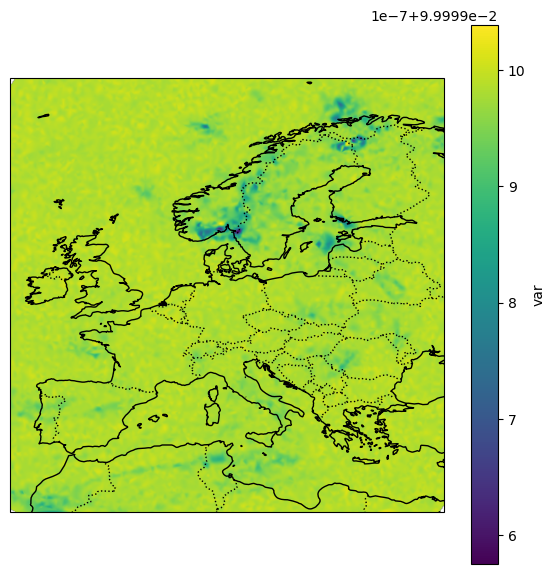

In [67]:
dataset = 'output'

dat = pd.DataFrame({'var': affinities[dataset].mean(axis=1)})
dat = pd.concat([locations, dat], axis=1)
fig = scalar_plot(dat, 'var', figsize=figsize)

In [11]:
graph.meta.feature_distances.detach().cpu().numpy().

torch.Size([15000, 30])

# Output

In [17]:
print('predict results')
output = model(sample).detach().cpu().numpy()

predict results


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.012135623020816973..1.0882782240680515].


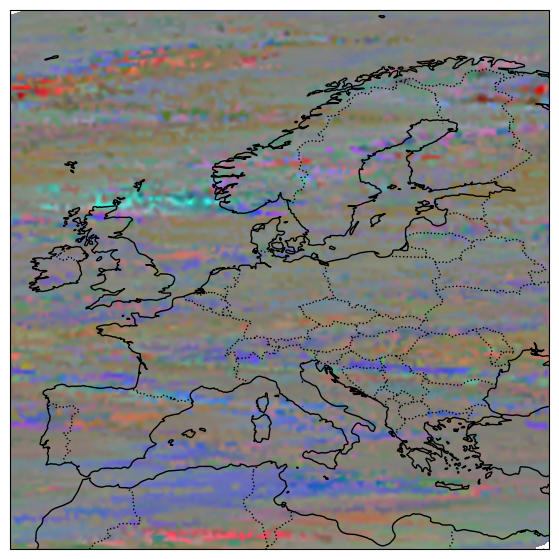

In [35]:
locations = pd.DataFrame({"lat": sample.meta.gps[:,0], "lon": sample.meta.gps[:,1]})

res_model = pd.DataFrame(
    {
        "x1": output[:, 0],
        "x2": output[:, 1],
        "x3": output[:, 2],
    }
)
res_model = pd.concat([locations, res_model], axis=1)

fig = rgb(res_model, figsize=figsize)
#fig = rgb_scale(res_model, percentile=1, figsize=figsize)

In [20]:
graph.keys()

['edge_dist',
 'x',
 'edge_index',
 'normed_values',
 'edge_attr',
 'meta',
 'sigmas',
 'normed_coords',
 'input_affinities']

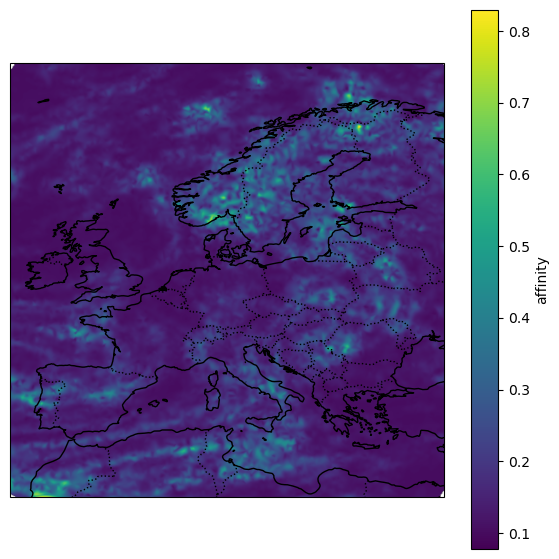

In [29]:
#out_affinities
out_affinities = get_output_affinities(torch.from_numpy(output).to(device='mps'), graph.edge_index)
affinity_magnitudes = out_affinities.detach().cpu().numpy().max(axis=1)
affinities = pd.DataFrame({"affinity" : affinity_magnitudes})
affinities = pd.concat([locations, affinities], axis=1)
fig = scalar_plot(affinities, 'affinity', figsize=figsize)

## Affinity distributions

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

In [34]:
aff_in = graph.input_affinities.detach().cpu().numpy()
aff_out = get_output_affinities(torch.from_numpy(output).to(device='mps'), graph.edge_index).detach().cpu().numpy()

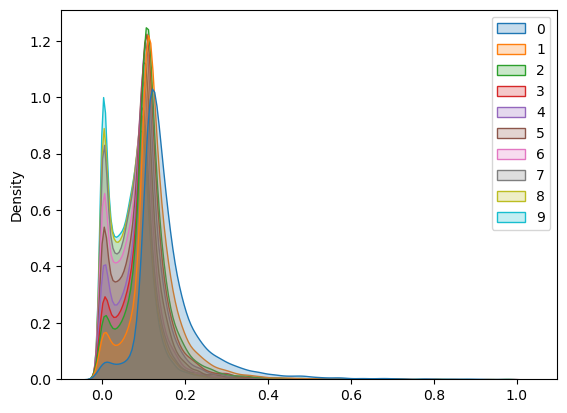

In [35]:
sns.kdeplot(aff_in, fill=True)
plt.show()

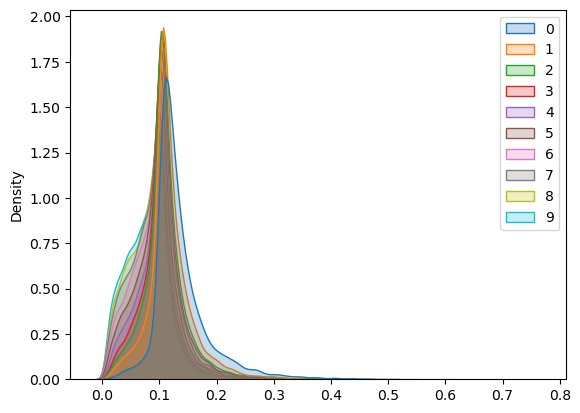

In [36]:
sns.kdeplot(aff_out, fill=True)
plt.show()

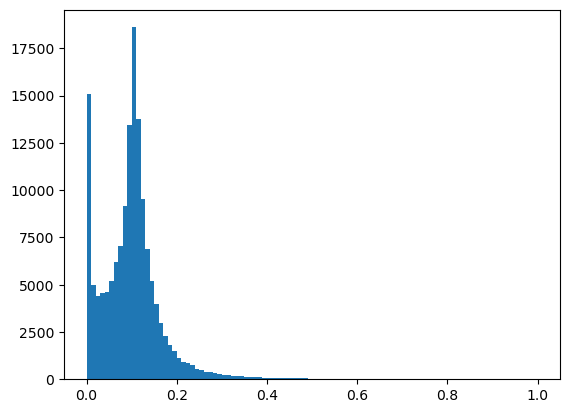

In [74]:
data = affinities['input'].flatten()
#data = affinities['input'][:,9]
fig = plt.hist(data, bins=100)

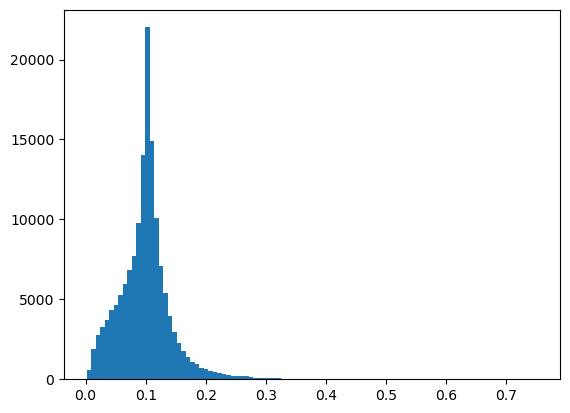

In [75]:
data = affinities['output'].flatten()
#data = affinities['output'][:,9]
fig = plt.hist(data, bins=100)

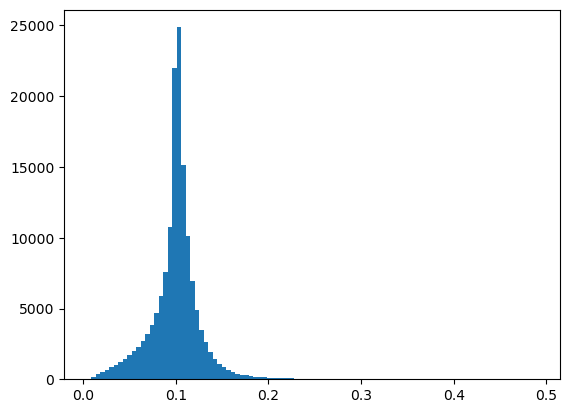

In [77]:
data = affinities['pca'].flatten()
#data = affinities['pca'][:,9]
fig = plt.hist(data, bins=100)